<a href="https://colab.research.google.com/github/sanhita24101/AIML/blob/main/AIML%20LAB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install network matplotlib

Graph (Adjacency List): {'A': ['B', 'C'], 'B': ['D', 'E'], 'C': ['F'], 'D': [], 'E': [], 'F': []}
BFS Traversal Order: ['A', 'B', 'C', 'D', 'E', 'F']
DFS Traversal Order: ['A', 'B', 'D', 'E', 'C', 'F']


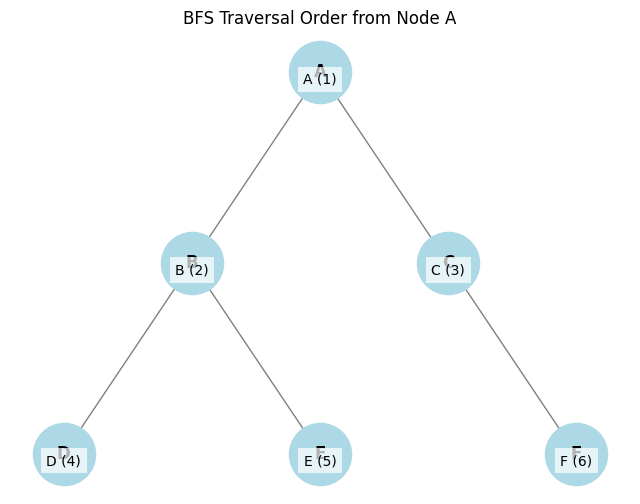

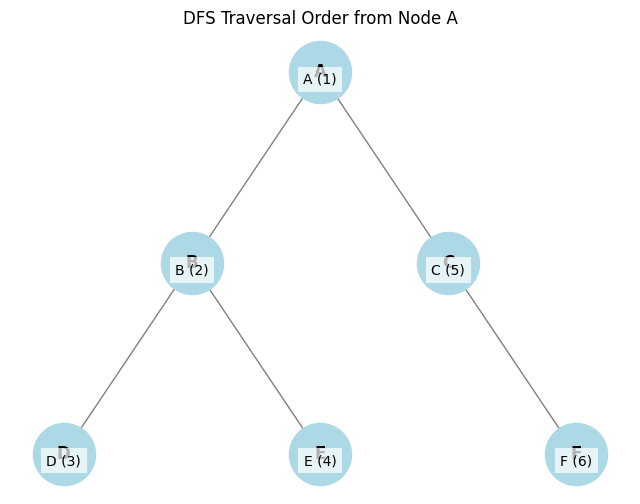

In [ ]:
import collections
import networkx as nx
import matplotlib.pyplot as plt

# 1. Stores the graph using an adjacency list (a python dictionary)
# Assuming a tree-like structure with A as the root
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': [],
    'F': []
}

print("Graph (Adjacency List):", graph)

# 2. Performs a BFS traversal starting from node A
def bfs(graph, start_node):
    visited = []  # To keep track of visited nodes
    queue = collections.deque([start_node])
    bfs_order = []

    while queue:
        node = queue.popleft()
        if node not in visited:
            visited.append(node)
            bfs_order.append(node)
            for neighbor in graph.get(node, []):
                if neighbor not in visited:
                    queue.append(neighbor)
    return bfs_order

# 3. Performs a DFS traversal starting from node A
def dfs(graph, start_node):
    visited = []  # To keep track of visited nodes
    stack = [start_node]
    dfs_order = []

    while stack:
        node = stack.pop()
        if node not in visited:
            visited.append(node)
            dfs_order.append(node)
            # Push neighbors in reverse order to maintain correct DFS order (LIFO)
            # This ensures that the left-most child is visited first if neighbors are sorted
            for neighbor in sorted(graph.get(node, []), reverse=True):
                if neighbor not in visited:
                    stack.append(neighbor)
    return dfs_order

# Perform traversals
bfs_result = bfs(graph, 'A')
dfs_result = dfs(graph, 'A')

# 4. Prints both traversal orders
print(f"BFS Traversal Order: {bfs_result}")
print(f"DFS Traversal Order: {dfs_result}")

# 5. Draws two separate tree diagrams
def draw_traversal_tree(graph_dict, traversal_order, title):
    G = nx.DiGraph()
    for node, neighbors in graph_dict.items():
        for neighbor in neighbors:
            G.add_edge(node, neighbor)

    # Create a mapping for node positions based on traversal order
    pos = {}
    y_level = 0
    x_offset = 0
    node_levels = {}
    queue = collections.deque([('A', 0)]) # (node, level)
    visited_levels = set()

    # Determine levels for a more tree-like layout
    while queue:
        node, level = queue.popleft()
        if node not in node_levels:
            node_levels[node] = level
            for neighbor in graph_dict.get(node, []):
                queue.append((neighbor, level + 1))

    # Assign positions based on traversal order and level
    nodes_by_level = collections.defaultdict(list)
    for node in traversal_order:
        nodes_by_level[node_levels[node]].append(node)

    max_level_width = 0
    for level in sorted(nodes_by_level.keys()):
        max_level_width = max(max_level_width, len(nodes_by_level[level]))

    for level in sorted(nodes_by_level.keys()):
        current_level_nodes = nodes_by_level[level]
        x_start = -(len(current_level_nodes) - 1) * 0.5
        for i, node in enumerate(current_level_nodes):
            pos[node] = (x_start + i, -level)

    plt.figure(figsize=(8, 6))
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2000)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True)
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')

    # Add traversal order labels
    labels = {}
    for i, node in enumerate(traversal_order):
        labels[node] = f'{node} ({i+1})'
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    plt.title(title)
    plt.axis('off')
    plt.show()

# Draw BFS traversal tree
draw_traversal_tree(graph, bfs_result, "BFS Traversal Order from Node A")

# Draw DFS traversal tree
draw_traversal_tree(graph, dfs_result, "DFS Traversal Order from Node A")


Found a solution to measure 2 litres:
Step 0: Initial state: (0, 0)
   Operation: Fill Jug B
Step 1: Current state: (0, 3)
   Operation: Pour B to A (3L)
Step 2: Current state: (3, 0)
   Operation: Fill Jug B
Step 3: Current state: (3, 3)
   Operation: Pour B to A (1L)
Step 4: Current state: (4, 2)


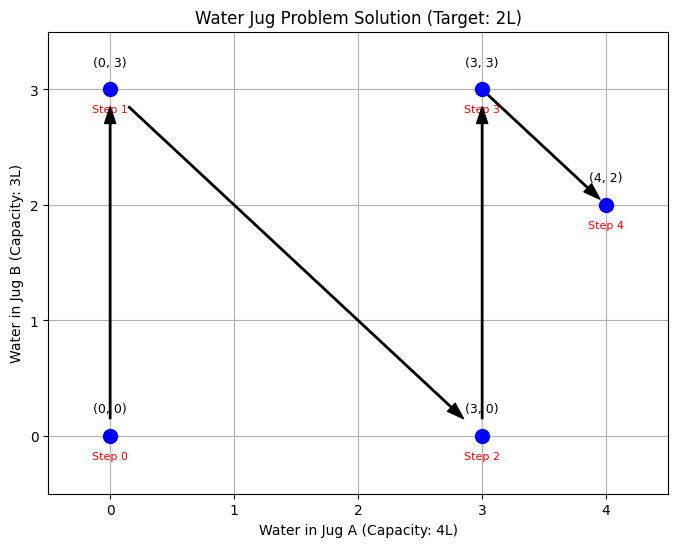

In [ ]:
import collections
import matplotlib.pyplot as plt

# Define jug capacities
CAP_A = 4 # Capacity of Jug A
CAP_B = 3 # Capacity of Jug B
TARGET = 2 # Target amount of water

def solve_water_jug_bfs(cap_a, cap_b, target):
    # State: (current_a, current_b)
    initial_state = (0, 0)
    queue = collections.deque([(initial_state, [])]) # (current_state, path_to_state)
    visited = {initial_state}

    while queue:
        (current_a, current_b), path = queue.popleft()

        # Check if target is reached
        if current_a == target or current_b == target:
            return path + [(current_a, current_b)]

        # Generate next possible states
        next_states = []

        # Operation 1: Fill Jug A
        next_states.append(((cap_a, current_b), path + [(current_a, current_b), 'Fill Jug A']))

        # Operation 2: Fill Jug B
        next_states.append(((current_a, cap_b), path + [(current_a, current_b), 'Fill Jug B']))

        # Operation 3: Empty Jug A
        next_states.append(((0, current_b), path + [(current_a, current_b), 'Empty Jug A']))

        # Operation 4: Empty Jug B
        next_states.append(((current_a, 0), path + [(current_a, current_b), 'Empty Jug B']))

        # Operation 5: Pour A to B
        # Amount that can be poured = min(water in A, space in B)
        pour_amount = min(current_a, cap_b - current_b)
        next_states.append(((current_a - pour_amount, current_b + pour_amount), path + [(current_a, current_b), f'Pour A to B ({pour_amount}L)']))

        # Operation 6: Pour B to A
        # Amount that can be poured = min(water in B, space in A)
        pour_amount = min(current_b, cap_a - current_a)
        next_states.append(((current_a + pour_amount, current_b - pour_amount), path + [(current_a, current_b), f'Pour B to A ({pour_amount}L)']))

        for next_state, next_path in next_states:
            if next_state not in visited:
                visited.add(next_state)
                queue.append((next_state, next_path))

    return None # No solution found

def plot_water_jug_solution(solution_path, cap_a, cap_b, target):
    if not solution_path:
        print("No solution path to plot.")
        return

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_title(f"Water Jug Problem Solution (Target: {target}L)")
    ax.set_xlabel(f"Water in Jug A (Capacity: {cap_a}L)")
    ax.set_ylabel(f"Water in Jug B (Capacity: {cap_b}L)")
    ax.set_xlim(-0.5, cap_a + 0.5)
    ax.set_ylim(-0.5, cap_b + 0.5)
    ax.set_xticks(range(cap_a + 1))
    ax.set_yticks(range(cap_b + 1))
    ax.grid(True)

    current_states = []
    for step in solution_path:
        if isinstance(step, tuple):
            current_states.append(step)

    # Plot states and transitions
    for i in range(len(current_states)):
        state_a, state_b = current_states[i]
        ax.plot(state_a, state_b, 'o', markersize=10, color='blue')
        ax.text(state_a, state_b + 0.2, f'({state_a}, {state_b})', fontsize=9, ha='center', color='black')
        ax.text(state_a, state_b - 0.2, f'Step {i}', fontsize=8, ha='center', color='red')

        if i > 0:
            prev_state_a, prev_state_b = current_states[i-1]
            ax.annotate('', xy=(state_a, state_b), xytext=(prev_state_a, prev_state_b),
                        arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8))

    plt.show()

# Solve the problem
solution_path = solve_water_jug_bfs(CAP_A, CAP_B, TARGET)

# Print the solution
if solution_path:
    print(f"Found a solution to measure {TARGET} litres:")
    for i, step in enumerate(solution_path):
        if i == 0:
            print(f"Step {i}: Initial state: {step}")
        elif isinstance(step, str):
            print(f"   Operation: {step}")
        else:
            print(f"Step {len(solution_path[:i])//2}: Current state: {step}")

    # Plot the solution
    plot_water_jug_solution(solution_path, CAP_A, CAP_B, TARGET)
else:
    print("No solution found for the given capacities and target.")


### Visualizing the Road Network and Connected Components

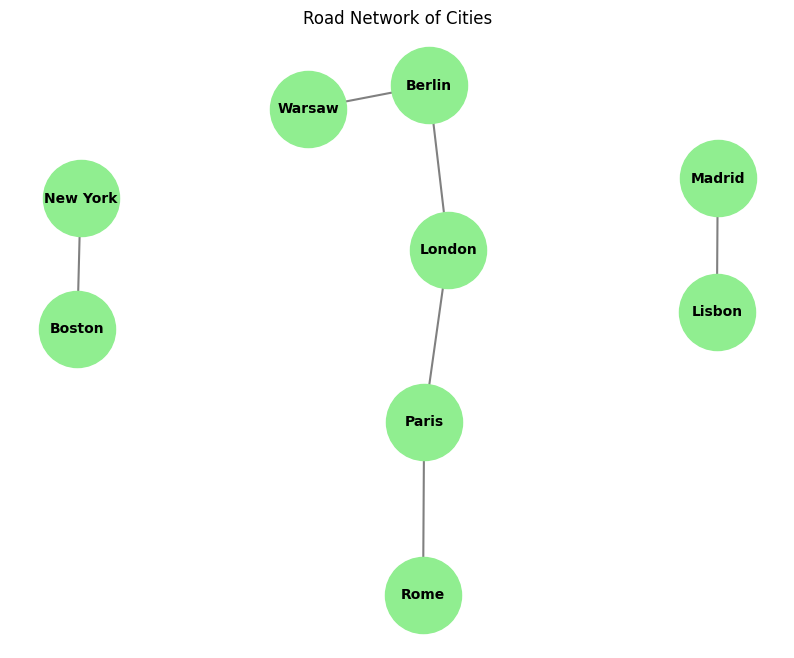

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Visualize the entire road network
G = nx.Graph(road_network) # Convert adjacency list to NetworkX graph

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, k=0.8, iterations=50) # Layout for better visualization
nx.draw_networkx_nodes(G, pos, node_color='lightgreen', node_size=3000)
nx.draw_networkx_edges(G, pos, edge_color='gray', width=1.5)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
plt.title("Road Network of Cities")
plt.axis('off')
plt.show()


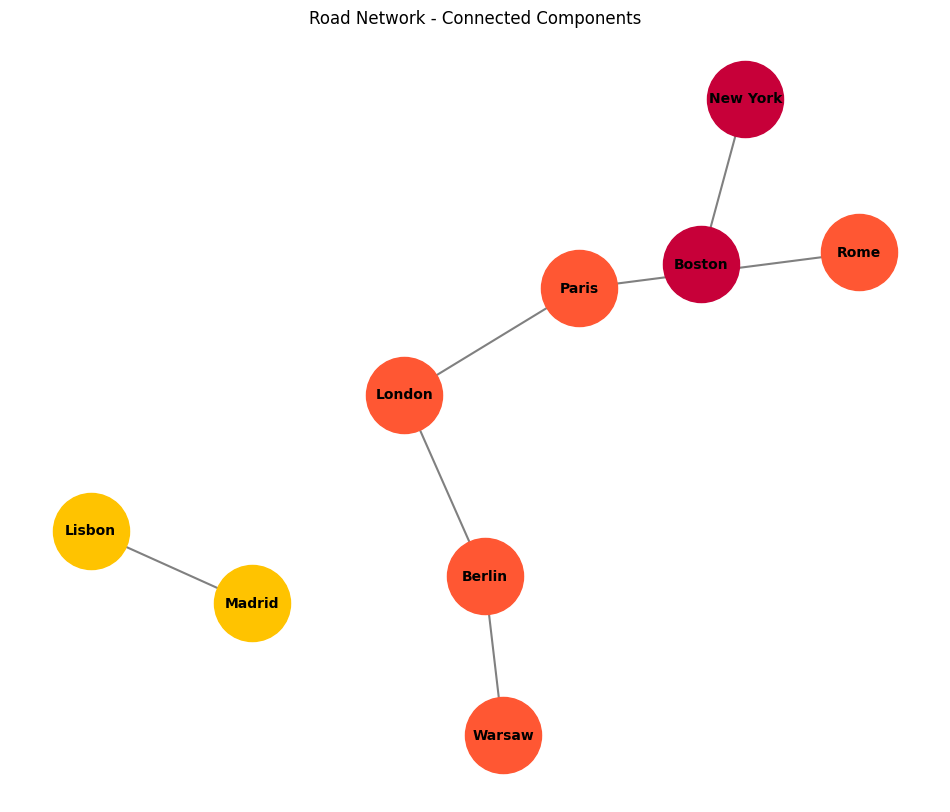

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Visualize connected components

# First, re-run the connected components function if it wasn't run recently or defined locally
# (Assuming find_connected_components and road_network are available from previous cells)
all_nodes = set(road_network.keys())
for neighbors in road_network.values():
    all_nodes.update(neighbors)

visited_global = set()
connected_components_viz = []

for node in all_nodes:
    if node not in visited_global:
        current_component = set()
        stack = [node]
        visited_local = set()

        while stack:
            current = stack.pop()
            if current not in visited_local:
                visited_local.add(current)
                current_component.add(current)
                for neighbor in road_network.get(current, []):
                    if neighbor not in visited_local and neighbor not in visited_global:
                        stack.append(neighbor)

        if current_component:
            connected_components_viz.append(list(current_component))
            visited_global.update(current_component)


G_cc = nx.Graph(road_network)

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_cc, k=0.8, iterations=50) # Layout for better visualization

colors = ['#FFC300', '#FF5733', '#C70039', '#900C3F', '#581845', '#DAF7A6', '#3498DB', '#E74C3C'] # More distinct colors

for i, component in enumerate(connected_components_viz):
    color = colors[i % len(colors)]
    nx.draw_networkx_nodes(G_cc, pos, nodelist=component, node_color=color, node_size=3000)

nx.draw_networkx_edges(G_cc, pos, edge_color='gray', width=1.5)
nx.draw_networkx_labels(G_cc, pos, font_size=10, font_weight='bold')
plt.title("Road Network - Connected Components")
plt.axis('off')
plt.show()
